In [4]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs           
import cartopy.feature as cfeature  
%matplotlib inline

In [2]:
#1.Global Earthquakes
df = pd.read_csv('usgs_earthquakes.csv')
df.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ml,NaN,NaN,NaN,0.2900,ak,ak11155107,2014-02-05T19:34:41.515Z,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,ml,4.0,171.43,0.34200,0.0247,nn,nn00436847,2014-02-01T01:35:09.000Z,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ml,NaN,NaN,NaN,1.0000,ak,ak11151142,2014-02-01T00:03:53.010Z,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ml,NaN,NaN,NaN,1.0700,ak,ak11151135,2014-01-31T23:41:25.007Z,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ml,6.0,285.00,0.04321,0.2000,ci,ci37171541,2014-02-01T00:13:20.107Z,"10km WNW of Progreso, Mexico",earthquake


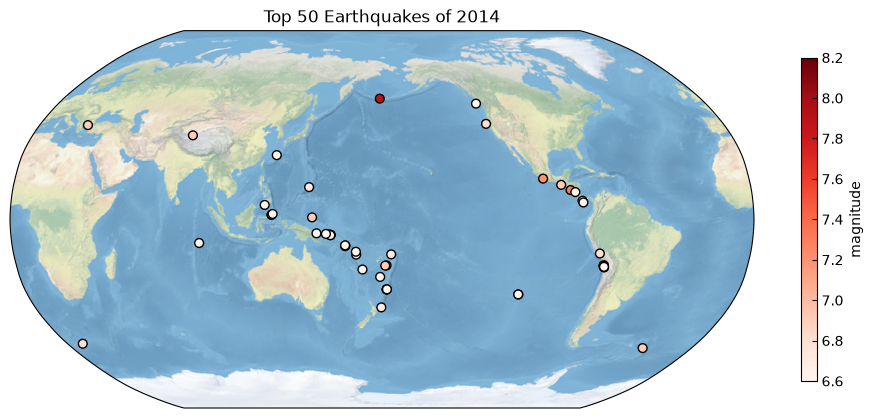

In [11]:
df['time'] = pd.to_datetime(df['time'])
df2014=df[df['time'].dt.year == 2014].copy()
x1=df2014.sort_values(by='mag', ascending=False).head(50)

fig = plt.figure(figsize=(12, 7))

ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))#设置投影
ax.stock_img()#设置纹理

# 绘制散点
scatter = ax.scatter(
    x1['longitude'], 
    x1['latitude'], 
    c=x1['mag'], 
    cmap='Reds', 
    vmin=6.6, vmax=8.2,                    
    edgecolors='black',   
    s=40,
    linewidths=1,           
    transform=ccrs.PlateCarree(), 
)

# 添加颜色条
cbar=plt.colorbar(scatter, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label('magnitude')
cbar.ax.tick_params(direction='in') # 刻度朝内

plt.title('Top 50 Earthquakes of 2014')#添加标题
plt.show()

In [27]:
#2. Explore a netCDF dataset（使用PS3数据）
ds1= xr.open_dataset("tco_epic_monthly_v1_jan2015_to_dec2024_1by1.nc")
time_datetime = pd.to_datetime(ds1['Time'], format='%b%Y')
ds1 = ds1.assign_coords(Time=time_datetime)
ds1['TropoO3']=ds1['TropoO3'].where((ds1['TropoO3']>0) & (ds1['TropoO3']<10000))
ds1.head()

<xarray.Dataset> Size: 580B
Dimensions:    (Time: 5, Latitude: 5, Longitude: 5)
Coordinates:
  * Time       (Time) datetime64[us] 40B 2015-01-01 2015-02-01 ... 2015-05-01
  * Latitude   (Latitude) float32 20B -89.5 -88.5 -87.5 -86.5 -85.5
  * Longitude  (Longitude) float32 20B -179.5 -178.5 -177.5 -176.5 -175.5
Data variables:
    TropoO3    (Time, Latitude, Longitude) float32 500B nan nan nan ... nan nan

In [28]:
ozone_data = ds1['TropoO3'].mean(dim='Time') 
print( ozone_data.min().values, ozone_data.max().values)

6.686022 79.64099


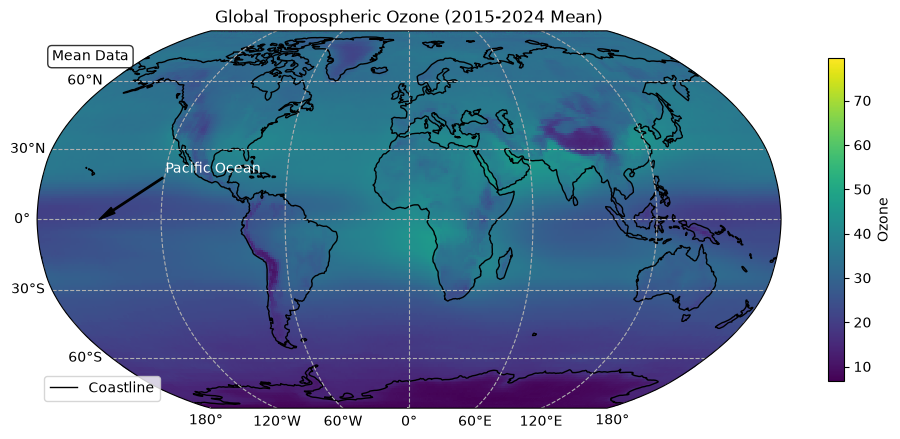

In [29]:
#2.1Make a global map
fig = plt.figure(figsize=(12, 7))
#1.投影
ax = plt.axes(projection=ccrs.Robinson()) 
#2.地理要素--海岸线
ax.add_feature(cfeature.COASTLINE)        

# 绘制数据
plot=ax.pcolormesh(ozone_data['Longitude'], ozone_data['Latitude'], ozone_data, 
                     cmap='viridis', transform=ccrs.PlateCarree(), shading='auto')

#3.网格线
grid= ax.gridlines(draw_labels=True, linestyle='--')
grid.top_labels = False
grid.right_labels = False

#4.颜色条与5.6.XY轴标签和刻度（经纬度）
c= plt.colorbar(plot, ax=ax, orientation='vertical', shrink=0.6)
c.set_label('Ozone')

#7.标题
plt.title('Global Tropospheric Ozone (2015-2024 Mean)')

#8.图例
ax.plot([], [], color='black', linewidth=1, label='Coastline')#给海岸线加一个图例
ax.legend(loc='lower left')

#9.注释
ax.annotate('Pacific Ocean', xy=(-150, 0), xytext=(-120, 20),
            arrowprops=dict(facecolor='black', width=1, headwidth=5),
            transform=ccrs.PlateCarree(), color='white')

#10.文本框
ax.text(0.02, 0.95, 'Mean Data', transform=ax.transAxes,
        va='top',  
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.show()

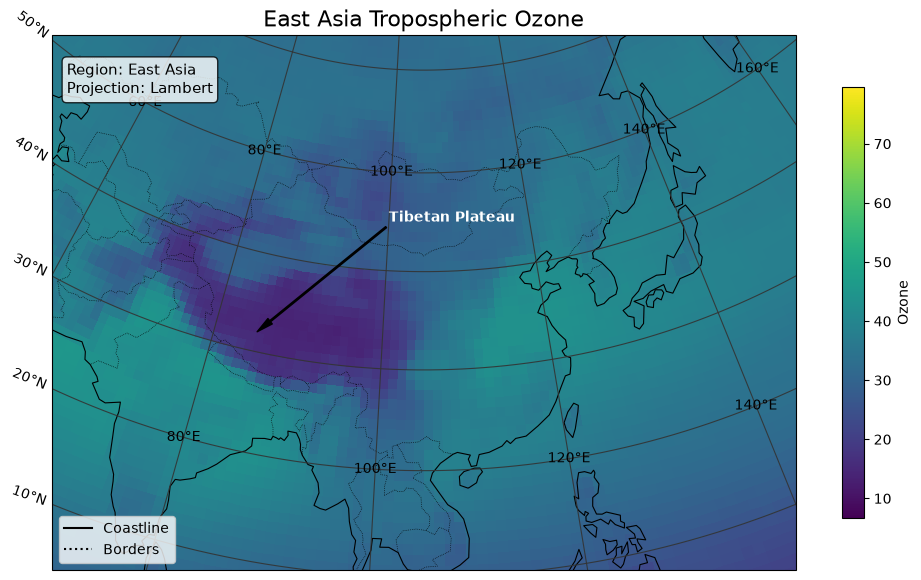

In [31]:
#2.2绘制区域图 
fig = plt.figure(figsize=(12, 8))

#1.投影 
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=105))

plot = ax.pcolormesh(ozone_data['Longitude'], ozone_data['Latitude'], ozone_data, 
                     cmap='viridis', transform=ccrs.PlateCarree(), shading='auto')

#截取东亚范围 (经度 70~140，纬度 10~60)
ax.set_extent([70, 140, 10, 60], crs=ccrs.PlateCarree())

#2.3.4.网格线与XY轴标签 
grid = ax.gridlines(draw_labels=True, linestyle='-', color='#333333', alpha=0.9)
grid.top_labels = False
grid.right_labels = False

#5.海岸线与国界
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)

#6.颜色条
c = plt.colorbar(plot, ax=ax, orientation='vertical', shrink=0.7)
c.set_label('Ozone')

#7.标题
plt.title('East Asia Tropospheric Ozone', fontsize=16)

#8.图例
ax.plot([], [], color='black', label='Coastline')
ax.plot([], [], color='black', linestyle=':', label='Borders')
ax.legend(loc='lower left')

#9.注释
ax.annotate('Tibetan Plateau', xy=(85, 32), xytext=(100, 45),
            arrowprops=dict(facecolor='black', width=1, headwidth=5),
            transform=ccrs.PlateCarree(), color='white', fontweight='bold')

#10.文本框
ax.text(0.02, 0.95, 'Region: East Asia\nProjection: Lambert', 
        transform=ax.transAxes, fontsize=11, va='top',
        bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.8))

plt.show()